In [ ]:

# Project: Financial Inclusion under PMJDY
# Student: Nancy Singh

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:


url = "https://www.pmjdy.gov.in/statewise-statistics"

try:
    tables = pd.read_html(url)

    print("Number of tables found:", len(tables))

    for i, table in enumerate(tables):
        print(f"\nTable {i}: {table.shape}")
        print(table.head(3))

except Exception as e:
    print("Data could not be loaded automatically.")
    print("Error:", e)

Data could not be loaded automatically.
Error: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'www.pmjdy.gov.in'. (_ssl.c:1032)>


In [ ]:

import pandas as pd

url = "https://pmjdy.gov.in/statewise-statistics"

try:
    tables = pd.read_html(url)
    print("Tables found:", len(tables))

    for i, table in enumerate(tables):
        print(f"\nTable {i}")
        print(table.head())

except Exception as e:
    print("Error:", e)

Tables found: 3

Table 0
   S.No                   State Name  \
0     1  Andaman And Nicobar Islands   
1     2               Andhra Pradesh   
2     3            Arunachal Pradesh   
3     4                        Assam   
4     5                        Bihar   

   Beneficiaries at rural/semi-urban centre bank branches  \
0                                              47935        
1                                           12697164        
2                                             460417        
3                                           23390084        
4                                           61569003        

   Beneficiaries at urban/metro centre bank branches  Total Beneficiaries  \
0                                              18544                66479   
1                                            4748980             17446144   
2                                              11754               472171   
3                                            2722952       

In [ ]:


# Step 4: Prepare the official PMJDY state-wise dataset

df = tables[0].copy()

# Clean column names
df.columns = df.columns.str.strip()

# Remove serial number column
df = df.drop(columns=["S.No"], errors="ignore")

# Remove extra spaces from state names
df["State Name"] = df["State Name"].astype(str).str.strip()

# Convert numeric columns into numeric data types
numeric_columns = [
    "Beneficiaries at rural/semi-urban centre bank branches",
    "Beneficiaries at urban/metro centre bank branches",
    "Total Beneficiaries",
    "Balance in beneficiary accounts (in crore)",
    "No. of RuPay cards issued to beneficiaries"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing values in the required fields
df = df.dropna(subset=["State Name"] + numeric_columns)

# Remove duplicate state names, if any
df = df.drop_duplicates(subset=["State Name"])

# Reset row numbering
df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows — check for any summary/total row:")
display(df.tail())

# Save the cleaned dataset
df.to_csv("PMJDY_Statewise_Cleaned.csv", index=False)

print("\nCleaned dataset saved successfully!")

Dataset shape: (37, 6)

Column names:
['State Name', 'Beneficiaries at rural/semi-urban centre bank branches', 'Beneficiaries at urban/metro centre bank branches', 'Total Beneficiaries', 'Balance in beneficiary accounts (in crore)', 'No. of RuPay cards issued to beneficiaries']

First 5 rows:


,State Name,Beneficiaries at rural/semi-urban centre bank branches,Beneficiaries at urban/metro centre bank branches,Total Beneficiaries,Balance in beneficiary accounts (in crore),No. of RuPay cards issued to beneficiaries
0,Andaman And Nicobar Islands,47935,18544,66479,59.21,40263
1,Andhra Pradesh,12697164,4748980,17446144,6921.18,11456985
2,Arunachal Pradesh,460417,11754,472171,278.15,319149
3,Assam,23390084,2722952,26113036,7854.09,16730292
4,Bihar,61569003,9169208,70738211,32587.05,50979789



Last 5 rows — check for any summary/total row:


,State Name,Beneficiaries at rural/semi-urban centre bank branches,Beneficiaries at urban/metro centre bank branches,Total Beneficiaries,Balance in beneficiary accounts (in crore),No. of RuPay cards issued to beneficiaries
32,Tripura,1048482,131815,1180297,738.18,663388
33,Uttar Pradesh,84272283,22608794,106881077,70433.19,74576257
34,Uttarakhand,2993387,1191375,4184762,3222.57,2880807
35,West Bengal,48461339,9424041,57885380,27843.55,38696127
36,Total,462693464,133200280,595893744,324069.14,417925654



Cleaned dataset saved successfully!


In [ ]:

# Step 6: Remove summary rows and verify the dataset

df["State Name"] = df["State Name"].astype(str).str.strip()

# Remove rows that represent totals, not individual states/UTs
df = df[
    ~df["State Name"].str.lower().isin(["total", "grand total", "all india"])
].copy()

df = df.reset_index(drop=True)

print("Rows after removing total:", len(df))
print("Unique state/UT names:", df["State Name"].nunique())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate state/UT names:")
print(df[df["State Name"].duplicated(keep=False)]["State Name"].tolist())

print("\nCheck whether rural + urban beneficiaries equal total:")
df["Calculated Total"] = (
    df["Beneficiaries at rural/semi-urban centre bank branches"]
    + df["Beneficiaries at urban/metro centre bank branches"]
)

print(
    "Rows with mismatched beneficiary totals:",
    (df["Calculated Total"] != df["Total Beneficiaries"]).sum()
)

df = df.drop(columns=["Calculated Total"])

# Save verified working data
df.to_csv("PMJDY_Statewise_Cleaned.csv", index=False)

display(df.head())

Rows after removing total: 36
Unique state/UT names: 36

Missing values:
State Name                                                0
Beneficiaries at rural/semi-urban centre bank branches    0
Beneficiaries at urban/metro centre bank branches         0
Total Beneficiaries                                       0
Balance in beneficiary accounts (in crore)                0
No. of RuPay cards issued to beneficiaries                0
dtype: int64

Duplicate state/UT names:
[]

Check whether rural + urban beneficiaries equal total:
Rows with mismatched beneficiary totals: 0


,State Name,Beneficiaries at rural/semi-urban centre bank branches,Beneficiaries at urban/metro centre bank branches,Total Beneficiaries,Balance in beneficiary accounts (in crore),No. of RuPay cards issued to beneficiaries
0,Andaman And Nicobar Islands,47935,18544,66479,59.21,40263
1,Andhra Pradesh,12697164,4748980,17446144,6921.18,11456985
2,Arunachal Pradesh,460417,11754,472171,278.15,319149
3,Assam,23390084,2722952,26113036,7854.09,16730292
4,Bihar,61569003,9169208,70738211,32587.05,50979789


In [ ]:

# Step 8: Create meaningful features for clustering

# Share of beneficiaries in rural/semi-urban centres
df["Rural Beneficiary Share (%)"] = (
    df["Beneficiaries at rural/semi-urban centre bank branches"]
    / df["Total Beneficiaries"] * 100
)

# Share of beneficiaries in urban/metro centres
df["Urban Beneficiary Share (%)"] = (
    df["Beneficiaries at urban/metro centre bank branches"]
    / df["Total Beneficiaries"] * 100
)

# Average account balance per beneficiary, in rupees
df["Average Balance per Beneficiary (Rs)"] = (
    df["Balance in beneficiary accounts (in crore)"]
    * 10_000_000
    / df["Total Beneficiaries"]
)

# RuPay cards issued per 100 beneficiaries
df["RuPay Cards per 100 Beneficiaries"] = (
    df["No. of RuPay cards issued to beneficiaries"]
    / df["Total Beneficiaries"] * 100
)

print("New features created successfully!")

display(df[[
    "State Name",
    "Total Beneficiaries",
    "Rural Beneficiary Share (%)",
    "Average Balance per Beneficiary (Rs)",
    "RuPay Cards per 100 Beneficiaries"
]].head(10))

print("\nFeature summary:")
display(df[[
    "Rural Beneficiary Share (%)",
    "Average Balance per Beneficiary (Rs)",
    "RuPay Cards per 100 Beneficiaries"
]].describe().round(2))

New features created successfully!


,State Name,Total Beneficiaries,Rural Beneficiary Share (%),Average Balance per Beneficiary (Rs),RuPay Cards per 100 Beneficiaries
0,Andaman And Nicobar Islands,66479,72.105477,8906.572000,60.564990
1,Andhra Pradesh,17446144,72.779200,3967.168906,65.670586
2,Arunachal Pradesh,472171,97.510648,5890.874281,67.591826
3,Assam,26113036,89.572442,3007.727635,64.068736
4,Bihar,70738211,87.037829,4606.711074,72.068248
5,Chandigarh,346631,14.766135,6518.170619,66.000156
6,Chhattisgarh,18928717,82.402553,4773.921022,61.759505
7,Delhi,7192953,9.197558,5753.408927,78.859406
8,Goa,241412,84.977135,10724.404752,71.916889
9,Gujarat,20221132,67.919046,6376.106936,76.715413



Feature summary:


,Rural Beneficiary Share (%),Average Balance per Beneficiary (Rs),RuPay Cards per 100 Beneficiaries
count,36.00,36.00,36.00
mean,74.11,6453.70,67.91
std,18.72,2847.70,6.16
min,9.20,2827.55,50.79
25%,69.08,4801.07,65.41
50%,76.43,5722.37,68.06
75%,85.49,6836.44,72.26
max,97.51,18433.93,78.86


In [ ]:
# Step 9: Select features and scale the data

# Log transformation reduces the effect of very large beneficiary counts
df["Log Total Beneficiaries"] = np.log1p(df["Total Beneficiaries"])

# Features used for clustering
features = [
    "Log Total Beneficiaries",
    "Rural Beneficiary Share (%)",
    "Average Balance per Beneficiary (Rs)",
    "RuPay Cards per 100 Beneficiaries"
]

X = df[features].copy()

# Standardize all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected:", features)
print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)
print("\nScaled data preview:")

display(pd.DataFrame(X_scaled, columns=features).head(10).round(2))

Features selected: ['Log Total Beneficiaries', 'Rural Beneficiary Share (%)', 'Average Balance per Beneficiary (Rs)', 'RuPay Cards per 100 Beneficiaries']
Original data shape: (36, 4)
Scaled data shape: (36, 4)

Scaled data preview:


,Log Total Beneficiaries,Rural Beneficiary Share (%),Average Balance per Beneficiary (Rs),RuPay Cards per 100 Beneficiaries
0,-1.62,-0.11,0.87,-1.21
1,0.70,-0.07,-0.89,-0.37
2,-0.80,1.27,-0.20,-0.05
3,0.87,0.84,-1.23,-0.63
4,1.28,0.70,-0.66,0.68
5,-0.93,-3.21,0.02,-0.31
6,0.73,0.45,-0.60,-1.01
7,0.33,-3.52,-0.25,1.80
8,-1.08,0.59,1.52,0.66
9,0.76,-0.34,-0.03,1.45


,Number of Clusters (K),Inertia,Silhouette Score
0,2,102.943,0.280
1,3,79.208,0.241
2,4,56.719,0.311
3,5,46.258,0.285
4,6,38.938,0.241


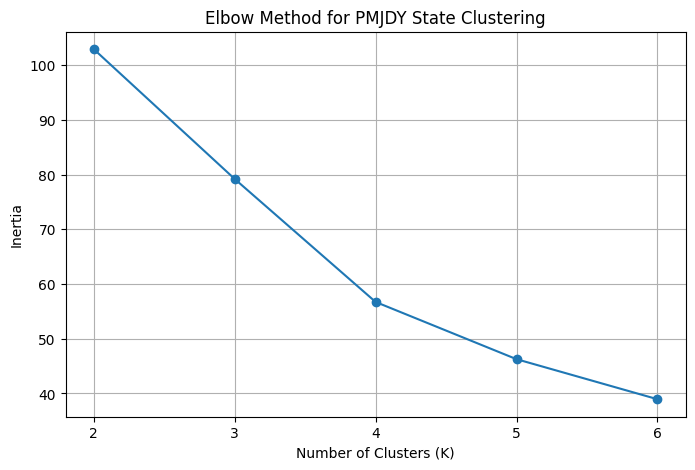

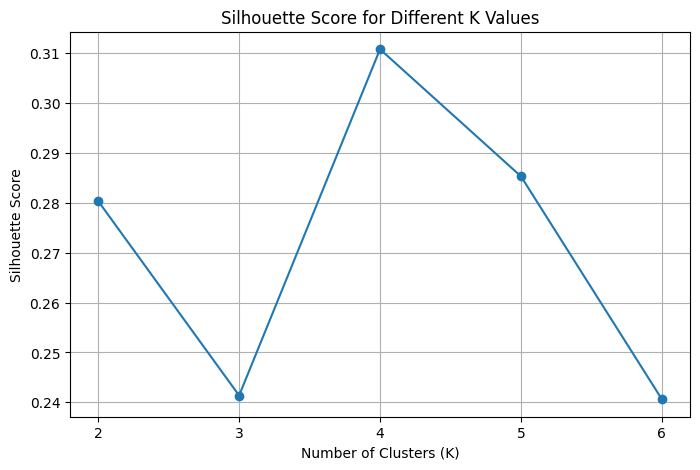

In [ ]:
# Step 10: Compare different numbers of clusters

inertia_values = []
silhouette_values = []
k_values = range(2, 7)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

results = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(results.round(3))

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for PMJDY State Clustering")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
# Step 11: Perform K-Means clustering with K = 4

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

df["KMeans_Cluster"] = kmeans_final.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("\nNumber of states/UTs in each cluster:")

display(
    df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Number of States/UTs")
)

print("\nState-wise cluster assignments:")

display(
    df[[
        "State Name",
        "Total Beneficiaries",
        "Rural Beneficiary Share (%)",
        "Average Balance per Beneficiary (Rs)",
        "RuPay Cards per 100 Beneficiaries",
        "KMeans_Cluster"
    ]].sort_values("KMeans_Cluster")
)

K-Means clustering completed!

Number of states/UTs in each cluster:


,Number of States/UTs
Cluster,
0,19
1,4
2,2
3,11



State-wise cluster assignments:


,State Name,Total Beneficiaries,Rural Beneficiary Share (%),Average Balance per Beneficiary (Rs),RuPay Cards per 100 Beneficiaries,KMeans_Cluster
1,Andhra Pradesh,17446144,72.779200,3967.168906,65.670586,0
3,Assam,26113036,89.572442,3007.727635,64.068736,0
6,Chhattisgarh,18928717,82.402553,4773.921022,61.759505,0
4,Bihar,70738211,87.037829,4606.711074,72.068248,0
13,Jharkhand,20838214,90.020723,6139.911991,68.420211,0
14,Karnataka,22276304,69.325634,6460.120135,62.707674,0
10,Haryana,11358820,57.544049,7503.147334,69.783138,0
9,Gujarat,20221132,67.919046,6376.106936,76.715413,0
24,Odisha,24388376,88.180459,5683.051631,74.157603,0
26,Punjab,10180257,62.630511,5534.290539,73.639752,0


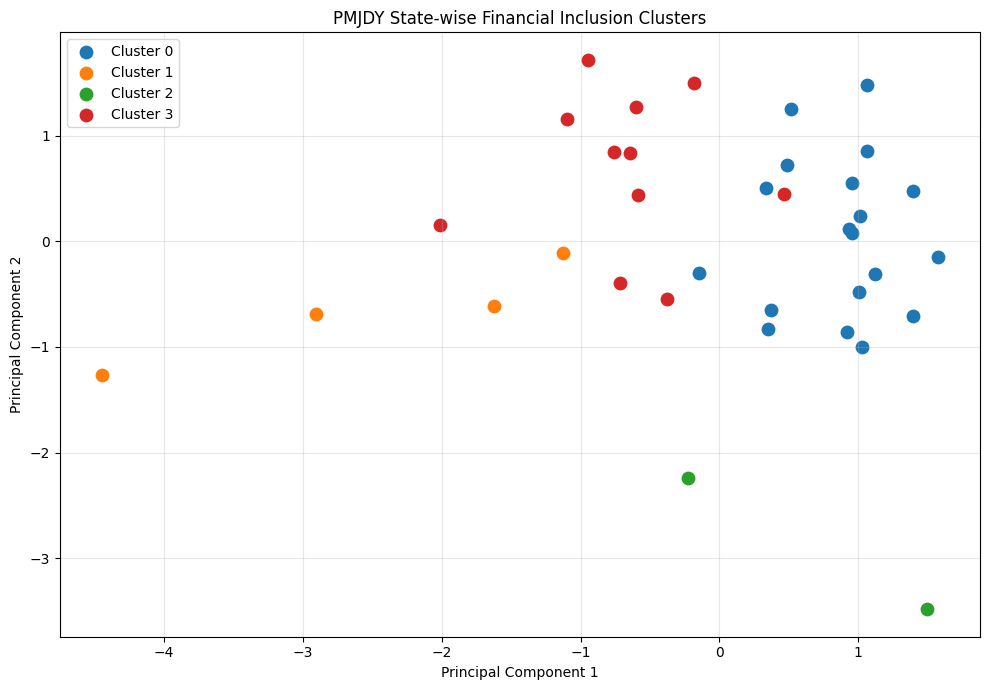

Variance explained by two PCA components: 69.62 %


In [ ]:
# Step 12: Visualize K-Means clusters using PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]

plt.figure(figsize=(10, 7))

for cluster in sorted(df["KMeans_Cluster"].unique()):
    cluster_data = df[df["KMeans_Cluster"] == cluster]

    plt.scatter(
        cluster_data["PCA1"],
        cluster_data["PCA2"],
        label=f"Cluster {cluster}",
        s=80
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PMJDY State-wise Financial Inclusion Clusters")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("PMJDY_KMeans_Clusters.png", dpi=300)
plt.show()

print(
    "Variance explained by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [ ]:
# Step 13: Analyse the characteristics of each cluster

cluster_profile = df.groupby("KMeans_Cluster").agg(
    Number_of_States=("State Name", "count"),
    Average_Beneficiaries=("Total Beneficiaries", "mean"),
    Average_Rural_Share=("Rural Beneficiary Share (%)", "mean"),
    Average_Balance_Rs=("Average Balance per Beneficiary (Rs)", "mean"),
    Average_RuPay_Indicator=("RuPay Cards per 100 Beneficiaries", "mean")
).round(2)

print("Cluster Profiles:")
display(cluster_profile)

# Save cluster assignments and profiles
df.to_csv("PMJDY_Clustered_States.csv", index=False)
cluster_profile.to_csv("PMJDY_Cluster_Profiles.csv")

print("Files saved successfully!")

Cluster Profiles:


,Number_of_States,Average_Beneficiaries,Average_Rural_Share,Average_Balance_Rs,Average_RuPay_Indicator
KMeans_Cluster,,,,,
0,19,30043600.89,75.57,5385.05,70.27
1,4,131215.50,86.30,12561.33,70.22
2,2,3769792.00,11.98,6135.79,72.43
3,11,1545534.64,78.44,6136.38,62.19


Files saved successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

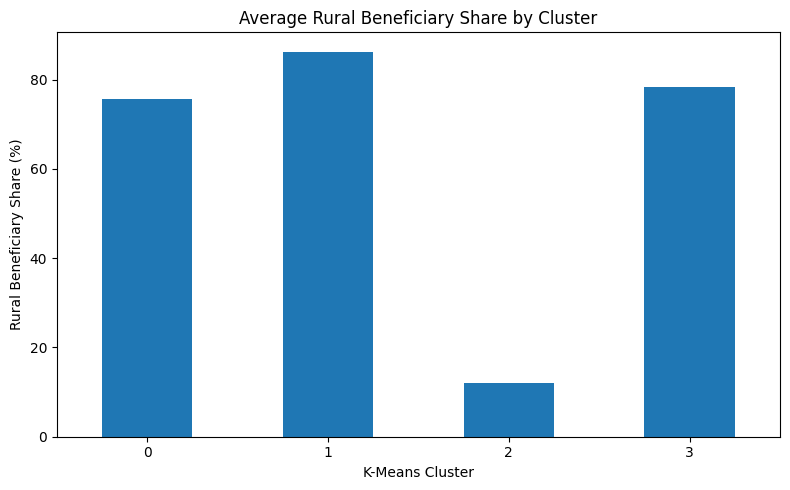

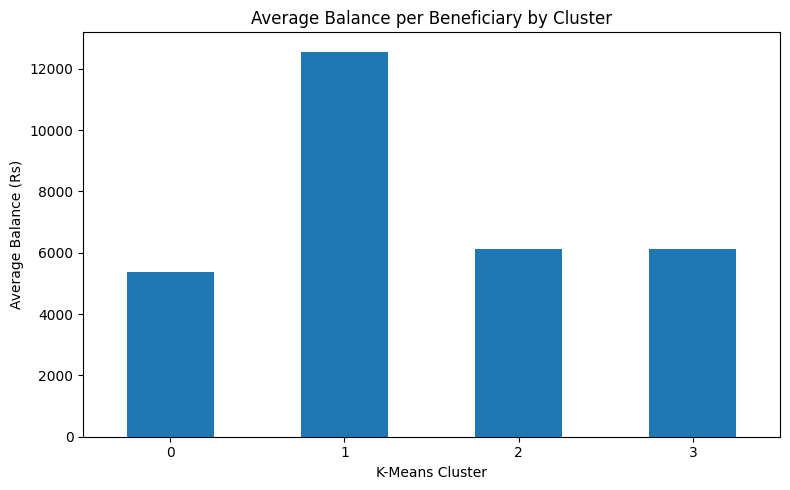

Final charts and CSV files saved successfully!

Saved files:
1. PMJDY_Clustered_States.csv
2. PMJDY_Cluster_Profiles.csv
3. PMJDY_KMeans_Clusters.png
4. PMJDY_Rural_Share_by_Cluster.png
5. PMJDY_Balance_by_Cluster.png


In [ ]:
# Step 15: Final charts and project outputs

# Chart 1: Average rural beneficiary share by cluster
plt.figure(figsize=(8, 5))

cluster_profile["Average_Rural_Share"].plot(
    kind="bar",
    rot=0
)

plt.title("Average Rural Beneficiary Share by Cluster")
plt.xlabel("K-Means Cluster")
plt.ylabel("Rural Beneficiary Share (%)")
plt.tight_layout()
plt.savefig("PMJDY_Rural_Share_by_Cluster.png", dpi=300)
plt.show()


# Chart 2: Average balance per beneficiary by cluster
plt.figure(figsize=(8, 5))

cluster_profile["Average_Balance_Rs"].plot(
    kind="bar",
    rot=0
)

plt.title("Average Balance per Beneficiary by Cluster")
plt.xlabel("K-Means Cluster")
plt.ylabel("Average Balance (Rs)")
plt.tight_layout()
plt.savefig("PMJDY_Balance_by_Cluster.png", dpi=300)
plt.show()


# Save final dataset and cluster profile
df.to_csv("PMJDY_Clustered_States.csv", index=False)
cluster_profile.to_csv("PMJDY_Cluster_Profiles.csv")

print("Final charts and CSV files saved successfully!")
print("\nSaved files:")
print("1. PMJDY_Clustered_States.csv")
print("2. PMJDY_Cluster_Profiles.csv")
print("3. PMJDY_KMeans_Clusters.png")
print("4. PMJDY_Rural_Share_by_Cluster.png")
print("5. PMJDY_Balance_by_Cluster.png")